# TP - Clasificación Multiclase de Texto con Regresión Softmax
### Redes Neuronales / Deep Learning

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Objetivos
- Implementar un pipeline de preprocesamiento de texto **configurable** (stopwords, stemming, lematización, n-gramas).
- Implementar una **Regresión Softmax** (regresión logística multinomial) en PyTorch: una única capa lineal + `CrossEntropyLoss`, sin capas ocultas.
- Trackear el entrenamiento con **TensorBoard** y **MLflow**.
- Usar **Optuna** para buscar la mejor combinación de hiperparámetros de preprocesamiento *y* de entrenamiento en conjunto.

## Qué hay que completar
Los bloques marcados `# TODO` son los que tienen que completar ustedes. El resto ya está resuelto.

Esta notebook es individual/standalone: no tiene una sección de defensa grupal asociada.


## Resolución

**Alumno:** Facundo Tomás Cassano Nieto (legajo 65555)

## 0. Setup

In [1]:
!pip install -q mlflow optuna


In [2]:
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


Usando dispositivo: cpu


In [3]:
import os
import copy
import time
import logging
import warnings
import pandas as pd
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("mlflow").setLevel(logging.WARNING)
logging.getLogger("alembic").setLevel(logging.WARNING)
os.makedirs("figuras", exist_ok=True)
pd.set_option("display.max_colwidth", 120)

# Estilo de los gráficos
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8c8b86", "axes.labelcolor": "#2b2b29",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
CATEGORICA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
ORDINAL = {3: ["#86b6ef", "#2a78d6", "#0d366b"],
           4: ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"],
           5: ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]}
GRIS = "#8c8b86"
LN_K = None  # se completa cuando se conoce la cantidad de clases

print("PyTorch", torch.__version__, "| hilos de CPU:", torch.get_num_threads())
print("Optuna", optuna.__version__, "| MLflow", mlflow.__version__)


PyTorch 2.14.1+cpu | hilos de CPU: 8
Optuna 5.0.0 | MLflow 3.16.1


In [4]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Facu\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups

Usamos `remove=('headers', 'footers', 'quotes')` para sacar metadata que haría el problema "demasiado fácil" (por ejemplo, el header a veces incluye el nombre del newsgroup).

In [5]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


`fetch_20newsgroups` devuelve el dataset 20 Newsgroups ya partido en train (11.314 documentos) y test (7.532). La partición es por fecha, y los mensajes de test son posteriores a los de train. Eso hace que el test se parezca a lo que pasaría en un uso real, donde el modelo clasificaría mensajes nuevos.

`remove=("headers", "footers", "quotes")` saca los encabezados, las firmas y el texto citado de otros mensajes. Sin esto el modelo podría tomar atajos que no tengan que ver con el contenido como por ejemplo la línea `Newsgroups:` del encabezado, direcciones de mail, etc., y la exactitud daría alta pero no por los motivos que queremos.

In [6]:
# Exploración rápida antes de entrenar nada

conteo_train = np.bincount(newsgroups_train.target, minlength=NUM_CLASSES)
conteo_test = np.bincount(newsgroups_test.target, minlength=NUM_CLASSES)
dist = pd.DataFrame({"clase": class_names, "train": conteo_train, "test": conteo_test})
dist["% train"] = (100 * dist["train"] / dist["train"].sum()).round(2)
display(dist.sort_values("train"))

largos = np.array([len(t.split()) for t in newsgroups_train.data])
vacios = int((largos == 0).sum())
print(f"Palabras por documento (train): mediana = {np.median(largos):.0f}, "
      f"percentil 90 = {np.percentile(largos, 90):.0f}, máximo = {largos.max()}")
print(f"Documentos vacíos después de sacar headers/footers/quotes: {vacios} ({100 * vacios / len(largos):.1f} %)")

,clase,train,test,% train
19,talk.religion.misc,377,251,3.33
18,talk.politics.misc,465,310,4.11
0,alt.atheism,480,319,4.24
16,talk.politics.guns,546,364,4.83
17,talk.politics.mideast,564,376,4.98
4,comp.sys.mac.hardware,578,385,5.11
1,comp.graphics,584,389,5.16
6,misc.forsale,585,390,5.17
3,comp.sys.ibm.pc.hardware,590,392,5.21
2,comp.os.ms-windows.misc,591,394,5.22


Palabras por documento (train): mediana = 83, percentil 90 = 336, máximo = 11765
Documentos vacíos después de sacar headers/footers/quotes: 300 (2.7 %)


**Observaciones.**

- Las clases están casi balanceadas: 17 de las 20 tienen entre 4,8 % y 5,3 % del train. Las más chicas son `talk.religion.misc` (377 documentos, 3,3 %), `talk.politics.misc` (4,1 %) y `alt.atheism` (4,2 %).
- La mediana es de 83 palabras por documento. Y justamente, la normalización L2 del TF-IDF evita que los documentos largos dominen.
- Hay 300 documentos de train que quedan vacíos después de sacar los encabezados, firmas y citas, así que probablemente eran mensajes que solo citaban a otro.

## 2. Preprocesamiento configurable

Vamos a armar una función de preprocesamiento con estos hiperparámetros (todos van a formar parte de la búsqueda de Optuna más adelante):

- `remove_stopwords` (`True`/`False`): sacar palabras muy frecuentes y poco informativas (`the`, `is`, `and`, ...).
- `normalization` (`"none"` / `"stem"` / `"lemmatize"`):
  - `"none"`: no se normaliza la palabra.
  - `"stem"`: **stemming** con Porter Stemmer — corta la palabra a una raíz heurística (`"running"` → `"run"`, a veces resultados no son palabras reales: `"studies"` → `"studi"`).
  - `"lemmatize"`: **lematización** con WordNet — lleva la palabra a su forma de diccionario (`"running"` → `"run"`, `"studies"` → `"study"`), más lenta pero más "correcta" lingüísticamente.

### TODO 1: completar `preprocess_text`

Pasos esperados:
1. Tokenizar el texto con `word_tokenize`.
2. Pasar todo a minúsculas y quedarse solo con tokens alfabéticos (`token.isalpha()`), para descartar números y puntuación.
3. Si `remove_stopwords` es `True`, sacar los tokens que estén en el set de stopwords.
4. Según `normalization`, aplicar `stemmer.stem(token)`, `lemmatizer.lemmatize(token)`, o dejar el token igual.
5. Devolver los tokens unidos con espacios (un string, para poder pasárselo después a `TfidfVectorizer`).

In [7]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # Las stopwords se filtran antes de normalizar. La lista de NLTK está en forma de diccionario
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]
    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)


Para las stopwords, `[t for t in tokens if t not in STOP_WORDS]`. Para la normalización, se aplica `STEMMER.stem` o `LEMMATIZER.lemmatize` a cada token.

Las stopwords se sacan antes de normalizar porque la lista de NLTK está en forma de diccionario (`was`, `does`, `having`). Si primero se aplicara el stemming, `was` pasaría a `wa` y ya no coincidiría con la lista.

La función devuelve un string porque `TfidfVectorizer` espera texto, y por dentro lo vuelve a tokenizar con su `token_pattern` por defecto que descarta los tokens de una sola letra. Por eso `a` o `i` desaparecen aunque no se saquen las stopwords.

In [8]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


Lo que muestra la prueba:

- Sacar stopwords elimina `the`, `were`, `and` y `of`. De 13 tokens quedan 7.
- El stemming es mucho más agresivo: `studying` → `studi`, `conditions` → `condit`, `engines` → `engin`.
- La lematización con WordNet solo cambió los sustantivos (`researchers` → `researcher`, `processes` → `process`) y dejó igual `were`, `studying` y `running`. Esto pasa porque `WordNetLemmatizer.lemmatize` asume que la palabra es un sustantivo (`pos="n"`) si no se le indica otra cosa. Para lematizar verbos habría que etiquetar a cada token en base a qué función cumple gramaticalmente, y eso es muy largo como para hacerlo en preprocesamiento. Tal como está ahora, la lematización es mucho más suave que el stemming.

## 3. Vectorización TF-IDF

Convertimos los textos preprocesados en vectores numéricos con `TfidfVectorizer`. Como el preprocesamiento (tokenización, stopwords, normalización) ya lo hicimos nosotros, acá solo controlamos:

- `ngram_range`: `(1,1)` solo unigramas, o `(1,2)` unigramas + bigramas (captura algo de contexto, ej. `"new york"`).
- `max_features`: tamaño máximo del vocabulario (se queda con los términos más frecuentes).
- `min_df`: un término tiene que aparecer en al menos `min_df` documentos para entrar al vocabulario (filtra términos rarísimos / errores de tipeo).

### TODO 2: completar `vectorize_data`

In [9]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):
    # El vocabulario y los IDF se aprenden SOLO con train; test se transforma con lo aprendido
    vectorizer = TfidfVectorizer(ngram_range=ngram_range, max_features=max_features, min_df=min_df)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)
    return X_train, X_test, vectorizer


In [10]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


Agregué un `TfidfVectorizer` con los tres parámetros, `fit_transform` sobre train y `transform` sobre test.

`fit_transform` aprende el vocabulario (aplicando `min_df` y después quedándose con los términos más frecuentes `max_features`) y el IDF de cada término. `transform` usa ese mismo vocabulario e IDF sin recalcular nada. Las palabras de test que no están en el vocabulario simplemente se ignoran. Si el vectorizer se ajustara con todos los textos, el IDF y la elección de los términos estarían siendo influenciados por documentos que después se usan para evaluar, y eso hace que la métrica le vaya mejor de lo que tendría que ser, ya que tiene un sesgo. Por eso en la búsqueda el vectorizer se ajusta con el 80 % de train y en el entrenamiento final con el train completo, nunca con el test.

Con los valores por defecto, `TfidfVectorizer` usa IDF = ln((1 + N)/(1 + df)) + 1, `sublinear_tf=False` y `norm="l2"`. La normalización L2 deja cada documento con norma 1, entonces un documento largo y uno corto quedan en la misma escala y todas las componentes caen en el rango [0, 1]. En la práctica eso cumple el papel de normalizar las entradas.

## 4. Modelo: Regresión Softmax

La regresión softmax (regresión logística multinomial) es el modelo más simple posible para clasificación multiclase: **una sola capa lineal** que mapea el vector de entrada a un score (logit) por clase, sin ninguna no-linealidad ni capa oculta.

`CrossEntropyLoss` de PyTorch ya incluye internamente un `log_softmax` + `NLLLoss`, así que el modelo **no debe aplicar softmax en el forward** — hay que devolver los logits crudos.

### TODO 3: completar `SoftmaxRegression`

In [11]:
class SoftmaxRegression(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # Una sola capa lineal: W (num_classes x input_dim) y b (num_classes)
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        # Logits crudos sin aplicar softmax, la softmax la aplica CrossEntropyLoss por dentro
        return self.linear(x)


In [12]:
# Sanity check
_dummy = torch.randn(4, 50)
_model_check = SoftmaxRegression(input_dim=50, num_classes=20)
_out = _model_check(_dummy)
assert _out is not None and _out.shape == (4, 20), "Revisá SoftmaxRegression"
print("Shape de salida OK:", _out.shape)
print("Parámetros con input_dim=10.000:", sum(p.numel() for p in SoftmaxRegression(10_000, 20).parameters()))


Shape de salida OK: torch.Size([4, 20])
Parámetros con input_dim=10.000: 200020


Agregué `self.linear = nn.Linear(input_dim, num_classes)` y un `forward` que devuelve su salida.

`nn.Linear` guarda una matriz de 20 × D y un bias b de 20 componentes, y calcula h = xWᵀ + b para todo de una vez. Cada fila de W cumple el rol de ser el representante de una clase, y el logit de la clase k es el producto punto entre el documento y esa fila, más su bias.

El `forward` devuelve los logits sin softmax porque `nn.CrossEntropyLoss` ya hace `log_softmax` + `NLLLoss` por dentro. Para clasificar tampoco hace falta, ya que la softmax es monótona, así que el argmax de los logits coincide con el de las probabilidades.

PyTorch inicializa `nn.Linear` con una uniforme en ±1/√D. Si las entradas tienen norma 1, los logits iniciales son casi iguales y la softmax da algo muy parecido a la uniforme y la loss arranca cerca de ln(20) ≈ 2,996. Ese valor es la cross-entropy de un modelo que asigna 1/20 a cada clase, el equivalente multiclase del ln 2 del caso binario. Una curva que no baja de ahí indica que el modelo no aprendió nada.

## 5. Entrenamiento (ya resuelto)

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

In [13]:
%load_ext tensorboard

In [14]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_softmax_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="softmax",
                        verbose=True):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}

    for epoch in range(epochs):
        t0 = time.perf_counter()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total
        epoch_time = time.perf_counter() - t0  # solo la pasada de entrenamiento (forward + backward + step)

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        if verbose:
            print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
                  f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
                  f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} - {epoch_time:.2f} s")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
            writer.add_scalar("tiempo_por_epoca_s", epoch_time, epoch)
        # Solo si hay una corrida abierta
        if mlflow.active_run() is not None:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)

    return history


`to_tensor_dataset` pasa la matriz dispersa a densa (`X.toarray()`) y la convierte en `float32`. Las etiquetas van como `long` porque `CrossEntropyLoss` espera el índice de la clase, no un vector one-hot.
El `DataLoader` mezcla los datos en cada época (`shuffle=True`) y los entrega de a batches. En validación no se mezcla porque no cambia nada.
`zero_grad()` limpia el gradiente, `backward()` calcula ∂J/∂W y ∂J/∂b con autograd y `optimizer.step()` actualiza los parámetros con Adam. Es básicamente un descenso por gradiente con minibatches.
La loss de train de cada época es el promedio de las losses de los batches mientras los pesos se iban moviendo; la de validación se mide con los pesos del final de la época. Por eso en la primera época la loss de train puede quedar por encima de la de validación.

Agregué también para que mida el tiempo de entrenamiento de cada época (`history["epoch_time"]`), y el parámetro `verbose` y el chequeo de `mlflow.active_run()` antes de loguear, ya que si no el primer `mlflow.log_metric` de la búsqueda abría una corrida implícita que nunca se cerraba, y en el entrenamiento final `mlflow.start_run(run_name="softmax_final")` fallaba con `Exception: Run with UUID ... is already active`.

## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).

In [15]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


`objective(trial)` le pide a Optuna un valor para cada hiperparámetro (`suggest_categorical` para los discretos y `suggest_float(..., log=True)` para el learning rate), arma todo el pipeline con esos valores y devuelve un escalar que representa la accuracy de validación en la última de 5 épocas.

El sampler es TPE (Tree-structured Parzen Estimator). Los primeros trials son aleatorios, y a partir de ahí separa los trials ya corridos en "buenos" y "malos", estima para cada hiperparámetro una densidad en cada grupo y toma los valores donde el cociente buenos/malos es alto. Es la lógica de priori, evidencia y posteriori aplicada a la búsqueda, acá no usa gradientes (ya que los hiperparámetros no son derivables).

Había un problema con el código original, y es que el sampler no tenía semilla, así que en cada ejecución proponía otros trials y el resultado no se podía reproducir. Por eso agregué `TPESampler(seed=SEED)`.
Además cambié la cantidad de trials de 15 a 50, ya que TPE usa por defecto `n_startup_trials=10`, o sea que los primeros 10 trials son aleatorios. Con 15 trials quedaba que la parte guiada era de apenas 5 trials.

In [16]:
mlflow.set_experiment("optuna_softmax_20newsgroups")


def objective(trial):
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])
    lr = trial.suggest_float("lr", 1e-3, 1e-1, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    t0 = time.perf_counter()
    train_texts, test_texts = preprocessed_cache[(remove_stopwords, normalization)]
    # Partimos una porción de train como validación para la búsqueda (no usamos el test acá)
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, newsgroups_train.target, test_size=0.2, random_state=SEED,
        stratify=newsgroups_train.target,
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)
    t_vec = time.perf_counter() - t0

    model = SoftmaxRegression(input_dim=X_tr.shape[1], num_classes=NUM_CLASSES)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    writer = SummaryWriter(log_dir=f"runs/optuna/trial_{trial.number:02d}")
    with mlflow.start_run(run_name=f"trial_{trial.number:02d}"):
        mlflow.log_params(trial.params)
        history = train_softmax_model(model, train_loader, val_loader, optimizer, epochs=5, writer=writer,
                                      run_name=f"trial_{trial.number}", verbose=False)
        t_train = sum(history["epoch_time"])
        mlflow.log_metrics({"tiempo_vectorizacion_s": t_vec, "tiempo_entrenamiento_s": t_train,
                            "vocab_size": X_tr.shape[1]})
    writer.close()

    trial.set_user_attr("vocab_size", X_tr.shape[1])
    trial.set_user_attr("t_vectorizacion", t_vec)
    trial.set_user_attr("t_entrenamiento", t_train)
    trial.set_user_attr("val_acc_hist", history["val_acc"])
    trial.set_user_attr("val_loss_hist", history["val_loss"])
    trial.set_user_attr("train_acc_hist", history["train_acc"])
    return history["val_acc"][-1]


N_TRIALS = 50
t_busqueda = time.perf_counter()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
t_busqueda = time.perf_counter() - t_busqueda

print("Mejores hiperparámetros:", study.best_params)
print("Mejor accuracy de validación:", study.best_value)
print(f"Tiempo total de la búsqueda: {t_busqueda / 60:.1f} min")


[I 2026-10-01 13:40:55,213] A new study created in memory with name: no-name-f52c7ae6-0e65-4b21-aa16-9d464df3e15d
[I 2026-10-01 13:41:01,997] Trial 0 finished with value: 0.5961113566062749 and parameters: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 2000, 'min_df': 2, 'lr': 0.0026587543983272706, 'batch_size': 128}. Best is trial 0 with value: 0.5961113566062749.
[I 2026-10-01 13:41:09,708] Trial 1 finished with value: 0.6442775077330977 and parameters: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1_2gram', 'max_features': 5000, 'min_df': 2, 'lr': 0.016409286730647923, 'batch_size': 128}. Best is trial 1 with value: 0.6442775077330977.
[I 2026-10-01 13:41:15,097] Trial 2 finished with value: 0.7207247017233761 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 2, 'lr': 0.010968217207529524, 'batch_size': 128}. Best is trial 2 with value

Mejores hiperparámetros: {'remove_stopwords': False, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 5, 'lr': 0.014463145399348728, 'batch_size': 128}
Mejor accuracy de validación: 0.7357490057445868
Tiempo total de la búsqueda: 5.0 min


### 6.1 Análisis de la búsqueda de hiperparámetros

Primero veamos la tabla de trials ordenada por accuracy de validación, con los tiempos de cada uno.

In [17]:
df_trials = study.trials_dataframe(attrs=("number", "value", "duration", "params", "user_attrs"))
df_trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in df_trials.columns]
df_trials["duracion_s"] = df_trials["duration"].dt.total_seconds()
df_trials["s_por_epoca"] = df_trials["t_entrenamiento"] / 5

cols = ["number", "value", "remove_stopwords", "normalization", "ngram_range", "max_features", "min_df",
        "lr", "batch_size", "vocab_size", "t_vectorizacion", "s_por_epoca"]
tabla_trials = df_trials[cols].sort_values("value", ascending=False).reset_index(drop=True)

print("Los 10 mejores trials:")
display(tabla_trials.head(10).round(4))
print("Los 5 peores trials:")
display(tabla_trials.tail(5).round(4))

Los 10 mejores trials:


,number,value,remove_stopwords,normalization,ngram_range,max_features,min_df,lr,batch_size,vocab_size,t_vectorizacion,s_por_epoca
0,33,0.7357,False,stem,1gram,10000,5,0.0145,128,9431,1.3465,0.2629
1,37,0.7349,True,stem,1gram,10000,5,0.0174,128,9330,0.9669,0.2414
2,32,0.7335,False,stem,1gram,10000,5,0.0142,128,9431,1.3220,0.2226
3,42,0.7335,False,stem,1gram,10000,5,0.0144,64,9431,1.3412,0.2894
4,43,0.7331,False,stem,1gram,10000,5,0.0144,128,9431,1.3644,0.2595
5,31,0.7327,False,stem,1gram,10000,5,0.0099,128,9431,1.4271,0.2363
6,27,0.7318,False,stem,1gram,10000,2,0.0090,128,10000,1.3341,0.2219
7,36,0.7318,True,stem,1gram,10000,5,0.0112,32,9330,0.9358,0.4071
8,48,0.7318,False,stem,1gram,10000,5,0.0143,128,9431,1.3485,0.2252
9,45,0.7296,False,stem,1gram,10000,5,0.0183,64,9431,1.3547,0.2826


Los 5 peores trials:


,number,value,remove_stopwords,normalization,ngram_range,max_features,min_df,lr,batch_size,vocab_size,t_vectorizacion,s_por_epoca
45,19,0.6491,False,lemmatize,1gram,10000,2,0.0011,128,10000,1.3673,0.2300
46,34,0.6487,False,stem,1gram,2000,5,0.0238,128,2000,1.1502,0.1512
47,1,0.6443,False,stem,1_2gram,5000,2,0.0164,128,5000,3.8036,0.1762
48,17,0.6213,False,lemmatize,1gram,2000,2,0.0056,128,2000,1.1739,0.1334
49,0,0.5961,True,none,1gram,2000,2,0.0027,128,2000,0.8183,0.1372


La mejor configuración (trial 33) es no sacar las stopwords, stemming, solo unigramas, `max_features = 10000`, `min_df = 5`, lr ≈ 0,0145 y batch de 128, con un accuracy de 0,7357.

Los diez mejores trials tienen en común que todos usan stemming, unigramas y el vocabulario más grande permitido, y la mayoría (7 de 10) usa batch de 128.

Los peores trials tienen vocabulario chico o learning rate bajo. El peor de todos es el primer trial, que junta vocabulario de 2.000 y lr de 0,0027.

Para chequear que las diferencias entre los mejores trials son reales y no ruido, repito los tres mejores trials con 5 semillas distintas. La semilla cambia el split train/validación, la inicialización y el orden de los batches.

In [18]:
def repetir_trial(params, seed, epochs=5):

    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    ngram = (1, 1) if params["ngram_range"] == "1gram" else (1, 2)
    textos, _ = preprocessed_cache[(params["remove_stopwords"], params["normalization"])]
    tr_t, va_t, tr_y, va_y = train_test_split(textos, newsgroups_train.target, test_size=0.2,
                                              random_state=seed, stratify=newsgroups_train.target)
    X_tr, X_val, _ = vectorize_data(tr_t, va_t, ngram, params["max_features"], params["min_df"])
    tl = DataLoader(to_tensor_dataset(X_tr, tr_y), batch_size=params["batch_size"], shuffle=True)
    vl = DataLoader(to_tensor_dataset(X_val, va_y), batch_size=1024, shuffle=False)
    model = SoftmaxRegression(X_tr.shape[1], NUM_CLASSES)
    h = train_softmax_model(model, tl, vl, optim.Adam(model.parameters(), lr=params["lr"]), epochs, verbose=False)
    return h["val_acc"][-1]


top3 = sorted(study.trials, key=lambda t: t.value, reverse=True)[:3]
filas = []
for t in top3:
    accs = [repetir_trial(t.params, s) for s in range(5)]
    filas.append({"trial": t.number, "val_acc en la búsqueda": t.value, "media (5 semillas)": np.mean(accs),
                  "desvío": np.std(accs, ddof=1), "mín": np.min(accs), "máx": np.max(accs)})
ruido = pd.DataFrame(filas).round(4)
display(ruido)
_ = torch.manual_seed(SEED)


,trial,val_acc en la búsqueda,media (5 semillas),desvío,mín,máx
0,33,0.7357,0.7381,0.0082,0.7300,0.7472
1,37,0.7349,0.7377,0.0076,0.7304,0.7472
2,32,0.7335,0.7380,0.0083,0.7300,0.7472


Repitiendo cada configuración con 5 semillas, las tres dan casi lo mismo en promedio. Con esto puedo concluir que el orden entre los tres mejores trials es ruido. Tienen un desvío de aproximadamente 0,8 puntos, por lo que una diferencia de 0,2 puntos entre trials no dice nada. Lo mismo vale para buena parte del top 10, que entra en un rango de menos de 1 punto. De hecho, el 33 y el 32 son la misma configuración con casi el mismo learning rate, y el 37 solo cambia en que saca las stopwords.

In [19]:
# Tiempos de cada trial según los hiperparámetros que los afectan
print("Tiempo de preparación de datos (split + TF-IDF + paso a tensores densos) por n-gramas:")
display(df_trials.groupby("ngram_range")["t_vectorizacion"].agg(["mean", "min", "max", "count"]).round(2))
print("Segundos por época de entrenamiento según batch size y tamaño del vocabulario:")
display(df_trials.pivot_table(index="vocab_size", columns="batch_size", values="s_por_epoca", aggfunc="mean").round(3))


Tiempo de preparación de datos (split + TF-IDF + paso a tensores densos) por n-gramas:


,mean,min,max,count
ngram_range,,,,
1_2gram,3.40,2.88,4.10,11
1gram,1.25,0.82,1.57,39


Segundos por época de entrenamiento según batch size y tamaño del vocabulario:


batch_size,32,64,128
vocab_size,,,
2000,0.272,NaN,0.141
5000,0.312,0.216,0.178
9330,0.396,NaN,0.234
9431,NaN,0.292,0.236
10000,0.400,0.270,0.234


La preparación de datos depende casi solo de los n-gramas. Con unigramas tarda 1,25 s en promedio y con bigramas 3,40 s, casi 3 veces más, porque el vectorizador tiene que contar todos los pares de palabras consecutivas. Entrenar las 5 épocas de un trial lleva aproximadamente entre 0,7 y 1,9 s, así que en los trials con bigramas se tarda más en vectorizar que en entrenar. Vemos además que el tiempo por época baja bastante al agrandar el batch. Con 10.000 términos pasa de 0,400 s con batch 32 a 0,234 s con batch 128.

## 7. Entrenamiento final

Usamos los mejores hiperparámetros encontrados por Optuna, entrenamos con **todo** el train set y por más épocas, evaluando contra el test set real (que no se usó en la búsqueda).

In [20]:
best = study.best_params
BEST_REMOVE_SW = best["remove_stopwords"]
BEST_NORM = best["normalization"]
BEST_NGRAM = (1, 1) if best["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES = best["max_features"]
BEST_MIN_DF = best["min_df"]
BEST_LR = best["lr"]
BEST_BATCH_SIZE = best["batch_size"]
EPOCHS_FINAL = 20

train_texts_final, test_texts_final = preprocessed_cache[(BEST_REMOVE_SW, BEST_NORM)]
X_train_final, X_test_final, vectorizer_final = vectorize_data(
    train_texts_final, test_texts_final, BEST_NGRAM, BEST_MAX_FEATURES, BEST_MIN_DF
)

train_loader_final = DataLoader(to_tensor_dataset(X_train_final, newsgroups_train.target),
                                 batch_size=BEST_BATCH_SIZE, shuffle=True)
test_loader_final = DataLoader(to_tensor_dataset(X_test_final, newsgroups_test.target),
                                batch_size=BEST_BATCH_SIZE, shuffle=False)

model = SoftmaxRegression(input_dim=X_train_final.shape[1], num_classes=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=BEST_LR)
writer = SummaryWriter(log_dir="runs/softmax_final")

mlflow.set_experiment("softmax_20newsgroups")
with mlflow.start_run(run_name="softmax_final"):
    mlflow.log_params({
        "remove_stopwords": BEST_REMOVE_SW, "normalization": BEST_NORM,
        "ngram_range": str(BEST_NGRAM), "max_features": BEST_MAX_FEATURES, "min_df": BEST_MIN_DF,
        "lr": BEST_LR, "batch_size": BEST_BATCH_SIZE, "epochs": EPOCHS_FINAL,
    })
    history = train_softmax_model(model, train_loader_final, test_loader_final, optimizer,
                                   epochs=EPOCHS_FINAL, writer=writer, run_name="final")
    mlflow.pytorch.log_model(copy.deepcopy(model).to("cpu"), "model",
                             input_example=X_train_final[:2].toarray().astype(np.float32))
    #Tuve que corregir esta última línea con ayuda de una ia, porque me daba un error que no pude entender.
writer.close()


[final] Epoch 1/20 - train_loss: 2.3144 train_acc: 0.5811 - val_loss: 1.8902 val_acc: 0.6581 - 0.28 s
[final] Epoch 2/20 - train_loss: 1.3011 train_acc: 0.8360 - val_loss: 1.5108 val_acc: 0.6737 - 0.23 s
[final] Epoch 3/20 - train_loss: 0.8959 train_acc: 0.8824 - val_loss: 1.3494 val_acc: 0.6791 - 0.23 s
[final] Epoch 4/20 - train_loss: 0.6831 train_acc: 0.9091 - val_loss: 1.2700 val_acc: 0.6794 - 0.25 s
[final] Epoch 5/20 - train_loss: 0.5513 train_acc: 0.9258 - val_loss: 1.2268 val_acc: 0.6760 - 0.26 s
[final] Epoch 6/20 - train_loss: 0.4613 train_acc: 0.9376 - val_loss: 1.1972 val_acc: 0.6751 - 0.27 s
[final] Epoch 7/20 - train_loss: 0.3956 train_acc: 0.9474 - val_loss: 1.1816 val_acc: 0.6753 - 0.27 s
[final] Epoch 8/20 - train_loss: 0.3463 train_acc: 0.9534 - val_loss: 1.1710 val_acc: 0.6715 - 0.30 s
[final] Epoch 9/20 - train_loss: 0.3078 train_acc: 0.9594 - val_loss: 1.1666 val_acc: 0.6697 - 0.33 s
[final] Epoch 10/20 - train_loss: 0.2769 train_acc: 0.9633 - val_loss: 1.1632 val_

2026/10/01 13:46:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Con los mejores hiperparámetros se vectoriza de nuevo, ahora ajustando el TF-IDF con el train completo (11.314 documentos), y se entrena 20 épocas.

### 7.1 Dinámica del entrenamiento final

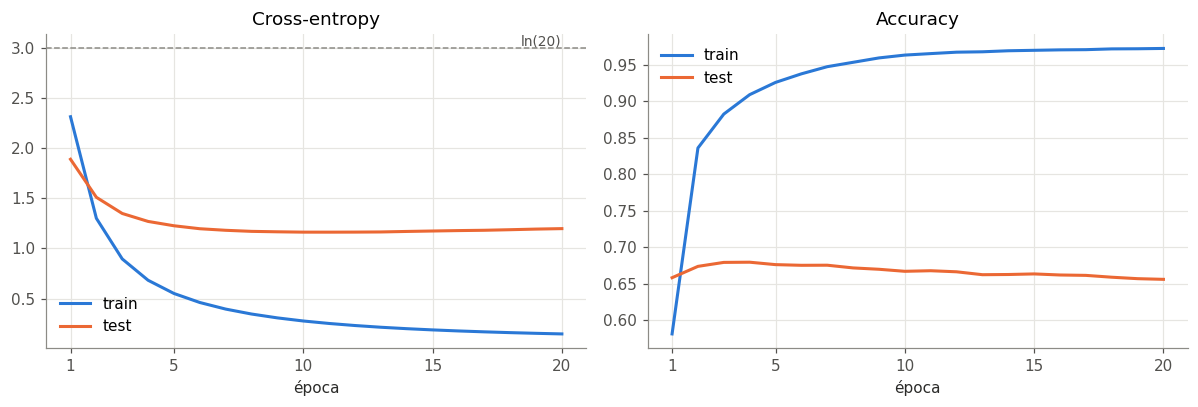

Mínimo de la loss de test: época 11 (1.1630)
Máximo de la accuracy de test: época 4 (0.6794)
Época 20: train_acc = 0.9724, test_acc = 0.6559, brecha = 0.3166
Época 20: train_loss = 0.1479, test_loss = 1.1983
Tiempo total de entrenamiento: 5.2 s (0.26 s por época)


In [21]:
LN_K = np.log(NUM_CLASSES)  # loss de un modelo que asigna 1/20 a cada clase
ep = np.arange(1, EPOCHS_FINAL + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ep, history["train_loss"], color=CATEGORICA[0], label="train")
axes[0].plot(ep, history["val_loss"], color=CATEGORICA[1], label="test")
axes[0].axhline(LN_K, color=GRIS, ls="--", lw=1)
axes[0].text(EPOCHS_FINAL, LN_K, "ln(20)", va="bottom", ha="right", color="#52514e", fontsize=9)
axes[0].set_title("Cross-entropy")
axes[1].plot(ep, history["train_acc"], color=CATEGORICA[0], label="train")
axes[1].plot(ep, history["val_acc"], color=CATEGORICA[1], label="test")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("época")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.legend()
plt.tight_layout()
plt.savefig("figuras/entrenamiento_final.png", bbox_inches="tight")
plt.show()

e_min_loss = int(np.argmin(history["val_loss"])) + 1
e_max_acc = int(np.argmax(history["val_acc"])) + 1
print(f"Mínimo de la loss de test: época {e_min_loss} ({min(history['val_loss']):.4f})")
print(f"Máximo de la accuracy de test: época {e_max_acc} ({max(history['val_acc']):.4f})")
print(f"Época 20: train_acc = {history['train_acc'][-1]:.4f}, test_acc = {history['val_acc'][-1]:.4f}, "
      f"brecha = {history['train_acc'][-1] - history['val_acc'][-1]:.4f}")
print(f"Época 20: train_loss = {history['train_loss'][-1]:.4f}, test_loss = {history['val_loss'][-1]:.4f}")
print(f"Tiempo total de entrenamiento: {sum(history['epoch_time']):.1f} s "
      f"({np.mean(history['epoch_time']):.2f} s por época)")


En las curvas se ve claramente el sobreajuste. La accuracy de train sube todo el tiempo y termina en 0,9724, mientras que la de test tiene su máximo en la época 4 (0,6794) y después baja de a poco hasta 0,6559. Con la loss pasa algo parecido, la de train sigue bajando y la de test baja hasta la época 11 y después sube un poco.

También se ve que la loss y la accuracy no tienen su mejor punto en la misma época (la accuracy en la 3, la loss en la 11). La accuracy de test (0,657) quedó bastante por debajo de la mejor de Optuna (0,736). No parece ser sesgo optimista de la búsqueda, porque en 6.1 la misma configuración repetida con 5 semillas dio 0,738 de promedio, incluso un poco más. Hay dos motivos más probables. Uno es que Optuna evaluó con 5 épocas y acá se entrenaron 20. El otro es que en este dataset los mensajes de test son posteriores a los de train, así que se parecen menos a lo que vio el modelo que los de la validación, que salieron del mismo train.

In [22]:
%tensorboard --logdir runs

## 8. Evaluación final

In [23]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader_final:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(yb.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
print(f"Accuracy en test: {test_accuracy:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Accuracy en test: 0.6559

                          precision    recall  f1-score   support

             alt.atheism       0.50      0.50      0.50       319
           comp.graphics       0.59      0.63      0.61       389
 comp.os.ms-windows.misc       0.58      0.60      0.59       394
comp.sys.ibm.pc.hardware       0.57      0.58      0.57       392
   comp.sys.mac.hardware       0.65      0.63      0.64       385
          comp.windows.x       0.73      0.63      0.67       395
            misc.forsale       0.74      0.78      0.76       390
               rec.autos       0.48      0.74      0.58       396
         rec.motorcycles       0.72      0.68      0.70       398
      rec.sport.baseball       0.84      0.79      0.82       397
        rec.sport.hockey       0.89      0.84      0.86       399
               sci.crypt       0.77      0.69      0.73       396
         sci.electronics       0.60      0.55      0.57       393
                 sci.med       0.75      0.72    

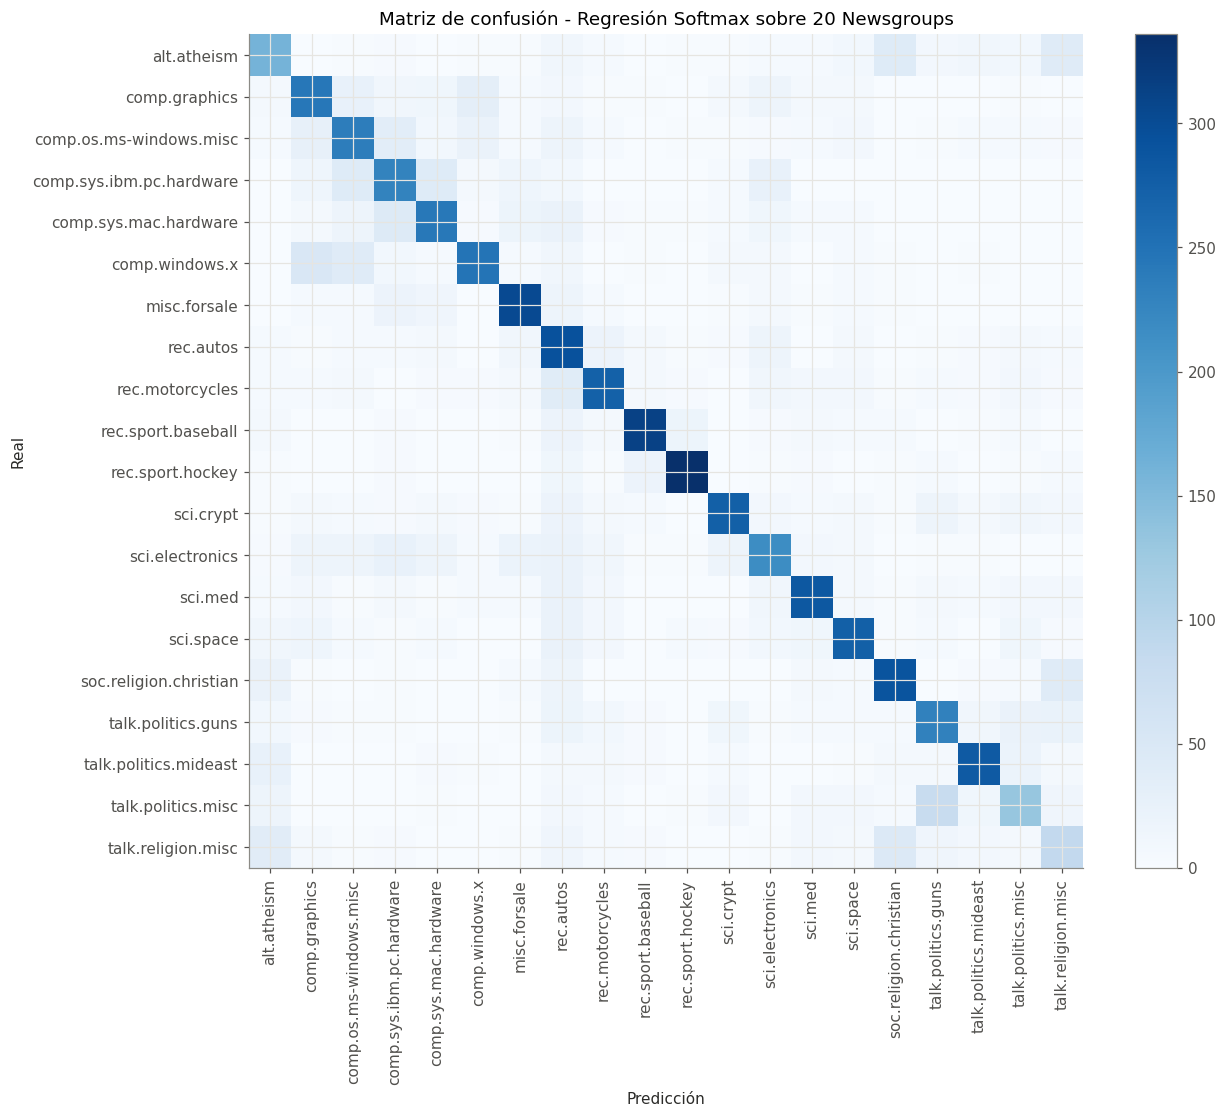

In [24]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.yticks(range(NUM_CLASSES), class_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Regresión Softmax sobre 20 Newsgroups")
plt.tight_layout()
plt.show()


In [25]:
print(f"Accuracy en test: {accuracy_score(all_labels, all_preds):.4f}")
print(f"Macro-F1 en test: {f1_score(all_labels, all_preds, average='macro'):.4f}")
print(f"Mejor val_acc de Optuna (5 épocas, 80 % del train): {study.best_value:.4f}")

# Pares (real -> predicha) que concentran más errores
cm_norm = cm / cm.sum(axis=1, keepdims=True)
pares = [(class_names[i], class_names[j], cm[i, j], 100 * cm_norm[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
df_pares = (pd.DataFrame(pares, columns=["real", "predicha", "casos", "% de la clase real"])
            .sort_values("casos", ascending=False).head(12).reset_index(drop=True))
df_pares["% de la clase real"] = df_pares["% de la clase real"].round(1)
print("\nLos 12 pares con más confusiones:")
display(df_pares)

recall_clase = pd.Series(np.diag(cm_norm), index=class_names, name="recall").sort_values()
print("Las 5 clases con peor recall:")
display(recall_clase.head(5).round(3).to_frame())

# Documentos que quedan como vector nulo (vacíos o sin ningún término del vocabulario)
vacios_test = np.where(X_test_final.getnnz(axis=1) == 0)[0]
preds_vacios = np.array(all_preds)[vacios_test]
print(f"Documentos de test sin ningún término del vocabulario: {len(vacios_test)} "
      f"({100 * len(vacios_test) / len(all_labels):.1f} %)")
print(f"  Predicción que reciben (logits = solo el bias): {sorted(set(class_names[p] for p in preds_vacios))}")
print(f"  Aciertos entre ellos: {int((preds_vacios == np.array(all_labels)[vacios_test]).sum())}")


Accuracy en test: 0.6559
Macro-F1 en test: 0.6479
Mejor val_acc de Optuna (5 épocas, 80 % del train): 0.7357

Los 12 pares con más confusiones:


,real,predicha,casos,% de la clase real
0,talk.politics.misc,talk.politics.guns,81,26.1
1,comp.windows.x,comp.graphics,50,12.7
2,talk.religion.misc,soc.religion.christian,45,17.9
3,comp.sys.mac.hardware,comp.sys.ibm.pc.hardware,42,10.9
4,comp.sys.ibm.pc.hardware,comp.sys.mac.hardware,41,10.5
5,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,41,10.5
6,alt.atheism,soc.religion.christian,41,12.9
7,soc.religion.christian,talk.religion.misc,40,10.1
8,comp.windows.x,comp.os.ms-windows.misc,40,10.1
9,alt.atheism,talk.religion.misc,40,12.5


Las 5 clases con peor recall:


,recall
talk.religion.misc,0.347
talk.politics.misc,0.426
alt.atheism,0.498
sci.electronics,0.550
comp.sys.ibm.pc.hardware,0.582


Documentos de test sin ningún término del vocabulario: 230 (3.1 %)
  Predicción que reciben (logits = solo el bias): ['rec.autos']
  Aciertos entre ellos: 24


En test el modelo da 0,656 de accuracy y 0,648 de macro-F1. Como las clases están casi balanceadas, los dos números son parecidos.

Las clases que mejor anda son las que tienen un vocabulario muy propio: `rec.sport.hockey` (F1 0,86), `rec.sport.baseball` (0,82), `talk.politics.mideast` (0,77) y `misc.forsale` (0,76). Son temas con palabras que casi no aparecen en otros grupos, como nombres de equipos, de países o de cosas en venta.

Y coincide que los errores están más que nada entre grupos que hablan de lo mismo: política, donde el par con más errores es `talk.politics.misc` predicho como `talk.politics.guns` (81 mensajes, 26,1%); religión, donde `talk.religion.misc` es la peor clase (recall 0,35). El 17,9% de sus mensajes se predice como `soc.religion.christian` y el 15,1% como `alt.atheism`. También están computación y vehículos (39 mensajes de `rec.motorcycles` se predicen como `rec.autos`). El problema es que son categorías que comparten mucho vocabulario.

## 9. Preguntas de reflexión

**Sobre Regresión Softmax (teoría)**
1. ¿Por qué la regresión softmax es una generalización de la regresión logística binaria? ¿Qué pasaría si `NUM_CLASSES = 2`?
2. ¿Por qué `CrossEntropyLoss` en PyTorch no necesita que se le aplique `softmax` antes en el forward? ¿Qué pasaría si igual lo aplicaran (softmax + CrossEntropyLoss)?
3. ¿Qué tipo de frontera de decisión puede aprender un modelo de regresión softmax? ¿Qué limitación tiene frente a un problema que no es linealmente separable?
4. ¿En qué se diferencia este modelo de una red neuronal con capas ocultas? ¿En qué situación elegirían una sobre la otra?

**Sobre frameworks y herramientas**
5. ¿Qué ventajas y desventajas tiene implementar esto en PyTorch (como hicimos) comparado con usar directamente `sklearn.linear_model.LogisticRegression(multi_class="multinomial")`?
6. ¿Para qué sirvió específicamente MLflow en este TP? ¿En qué se diferencia de lo que loguea TensorBoard?
7. ¿Qué ventaja concreta les dio Optuna frente a probar combinaciones de hiperparámetros a mano?

**Sobre el experimento**
8. ¿Qué combinación de preprocesamiento (stopwords, stemming/lematización, n-gramas) encontró Optuna como mejor? ¿Tiene sentido para este dataset?
9. ¿En qué categorías del dataset se confunde más el modelo (según la matriz de confusión)? ¿Por qué creen que pasa (piensen en el contenido temático de esas categorías)?
10. ¿Cambiaría su respuesta a la pregunta anterior si usaran un modelo con capas ocultas en vez de regresión softmax? ¿Por qué sí o por qué no?


### Respuestas

**Sobre regresión softmax (teoría)**

**1.** La regresión logística binaria pasa una función lineal por una sigmoidea, y la softmax generaliza eso a K clases, calcula un score exp(w_kᵀx + b_k) para cada clase y los normaliza para que sumen 1. El logodds entre dos clases queda (w_k − w_l)ᵀx + (b_k − b_l), que es lineal como en la regresión logística. Con `NUM_CLASSES = 2` queda

P(Y = 1 | x) = 1 / (1 + exp(−[(w₁ − w₀)ᵀx + (b₁ − b₀)]))

que es exactamente una sigmoidea con w = w₁ − w₀ y b = b₁ − b₀. El modelo funcionaría igual que una regresión logística, solo que con el doble de pesos, porque lo único que importa es la diferencia entre los dos vectores.

**2.** Porque `CrossEntropyLoss` ya aplica la softmax adentro: hace `log_softmax` y después `NLLLoss` en un solo paso. Están juntas ya que calcular primero las exponenciales y después el logaritmo por separado puede dar overflow o log(0) = −∞. Por eso el modelo devuelve los logits. Para clasificar da lo mismo, porque la softmax es creciente y el argmax de los logits es el mismo que el de las probabilidades.

Si se aplicara softmax en el forward, quedaría aplicada dos veces. Las salidas ya estarían entre 0 y 1, y la segunda softmax las dejaría casi iguales entre sí. De hecho, si miraramos el mejor de los casos, que sería que se le asigne 1 en la clase correcta y 0 en las otras 19, la probabilidad final de la clase correcta sería e / (e + 19) ≈ 0,125, así que la loss nunca podría bajar de −ln(0,125) ≈ 2,08 y el entrenamiento sería mucho más lento.

**3.** La frontera entre dos clases ocurre cuando sus logits son iguales, (w_k − w_l)ᵀx + (b_k − b_l) = 0. Con 20 clases el espacio queda dividido en regiones separadas por planos, o sea que la frontera es lineal. Si las clases no son linealmente separables, como en el caso que una clase rodee a otra, el modelo no puede representar la frontera correcta y se queda con el mejor hiperplano posible, que va a tener errores.

**4.** Una red con capas ocultas aplica una función de activación no lineal entre una capa y la siguiente. Con esa no linealidad, varias capas lineales colapsan en una sola y no se gana nada. En ese caso la frontera de decisión puede ser no lineal, y por el teorema de aproximación universal la red puede aproximar cualquier función continua. PERO la contra es que la función de costo deja de ser convexa, ya que aparecen mínimos locales, hay más hiperparámetros, el entrenamiento es más caro y el modelo tiene más varianza, así que necesitas más datos.

Eligiría regresión softmax cuando el problema es más o menos linealmente separable o cuando hay pocos datos para la cantidad de features o cuando importa poder interpretar los pesos. La red con capas ocultas conviene cuando la relación entre las variables no es lineal y hay datos suficientes.

**Sobre frameworks y herramientas**

**5.** Con scikit-learn el mismo `LogisticRegression` trabaja directamente con la matriz dispersa que devuelve `TfidfVectorizer`, regulariza por defecto y usa un optimizador que llega al mínimo del problema convexo sin que haya que elegir un learning rate, ni batch ni cantidad de épocas. En cambio PyTorch te permite controlar el entrenamiento, ya que tenés que elegir el optimizador, se puede ver la curva época por época, se puede hacer early stopping y usar GPU. La contra es que hay más código y más hiperparámetros para ajustar, además hay que pasar la matriz a densa (que ocupa más memoria) y la regularización hay que agregarla a mano.

**6.** MLflow sirvió para registrar cada entrenamiento como una corrida, con sus hiperparámetros, sus métricas y sus tiempos. Así se pueden comparar todas las corridas, ordenarlas por accuracy o filtrarlas desde `mlflow ui` sin volver a correr nada. TensorBoard, en cambio, sirve para mirar las curvas de loss y accuracy época por época de cada entrenamiento.

**7.** El problema con probar a mano es que hay demasiadas posibilidades y terminas cambiando una cosa por vez sin ver cómo interactúan ENTRE SÍ. En cambio Optuna hace una búsqueda bayesiana, ya que los primeros 10 trials son al azar y después usa los resultados anteriores para proponer valores en las zonas que vienen dando mejor. Se nota en la tabla de 6.1, donde los 10 mejores trials son todos de cuando la búsqueda ya estaba guiada.

**Sobre el experimento**

**8.** Optuna eligió no sacar las stopwords, stemming, solo unigramas, `max_features = 10000` y `min_df = 5`, con Adam, lr ≈ 0,0145 y batch de 128. Tiene sentido ya que el stemming junta variantes de una misma palabra, así que para vocabularios grandes te permite distinguir mejor palabras distintas. Sacar las stop-words no es tan importante ya que TF-IDF ya le baja el peso a las palabras que aparecen en todos los documentos, así que sacarlas a mano agrega poco. Por otro lado, los 10 mejores trials usan el vocabulario más grande permitido, y tres de los cinco peores usan sólo 2.000 términos, y tiene sentido que hayan sido los peores ya que con pocos términos, muchos mensajes quedan descritos por muy pocas palabras (lo que aumenta la probabilidad de que sean las mismas).

**9.** Según la matriz de confusión, el modelo se confunde sobre todo en cuatro grupos: política, religión, computación y vehículos. El de religión, por ejemplo, tiene sentido ya que todos hablan de Dios, la Biblia, etc., y la diferencia entre uno y otro suele ser la postura de la persona que escribe. Del lado de computación, es razonable que se solapen ya que todos hablan con el mismo vocabulario, que es muy técnico y específico, por lo que es difícil hallar sinónimos que los hagan discernibles. Lo mismo ocurre para la parte de vehículos. En casi todos los casos hay una categoría general (misc) que se superpone con otras más específicas. Además, coincide que las tres clases con peor recall (`talk.religion.misc`, `talk.politics.misc` y `alt.atheism`) son las que tienen menos documentos de entrenamiento.

**10.** Creo que no cambiaría mucho ya que las confusiones vienen de la representación tf-idf. Si un mensaje de `alt.atheism` y uno de `soc.religion.christian` usan las mismas palabras, sus vectores TF-IDF son parecidos y ningún modelo, lineal o no, los va a separar bien. Además el modelo ya llega a 0,97 en train, así una red con más parámetros sólo sobreajustaría más.